# 03 · ML: năng suất, bất thường, dự báo độ ẩm đất

Ba mô hình, ba câu hỏi:

1. **Yield regression** — năng suất quốc gia/năm từ đặc trưng khí hậu. Dữ liệu nhỏ (120 mẫu), nên đây là demo có kiểm chứng, không phải kết luận nông học.
2. **Anomaly detection** — tìm giờ/ngày bất thường trên 1.052.064 dòng hourly bằng Isolation Forest.
3. **Forecast** — dự báo độ ẩm đất 7 ngày bằng mô hình Ridge trên lag features, so với persistence.

Mọi metric được lưu vào `reports/` để notebook 04 dựng dashboard.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import *
ensure_dirs()
setup_matplotlib()

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from warehouse import connect, create_base_tables
from features import build_yield_features, build_anomaly_features, daily_series
from ml import (
    train_yield_models, fit_anomaly_model, score_injected_anomalies,
    known_event_check, top_anomalies, forecast_soil,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)


## 1. Feature table cho yield

Mỗi dòng là một **địa điểm–năm**. Các đặc trưng được tổng hợp từ 43.836 dòng daily: GDD, số ngày nóng, ngày sương giá, tổng mưa, đợt khô dài nhất, thống kê độ ẩm đất và độ ẩm không khí.

In [2]:
con = connect()
tables = {row[0] for row in con.execute("SHOW TABLES").fetchall()}
if "fact_weather_hourly" not in tables:
    create_base_tables(con)

features = build_yield_features(con)
features.to_csv(REPORTS_DIR / "yield_features.csv", index=False)
display(features.head(6))
print("shape:", features.shape, "| locations:", features.location_id.nunique(), "| years:", features.year.nunique())


,location_id,year,gdd,heat_days_35,frost_days,precip_total,dry_days,soil_mean,soil_min,soil_p95,rh_mean,max_dry_spell,country_iso3,country_name,latitude,longitude,crop_system,yield_kg_ha
0,AR-PER,2015,2600.85,2.0,7.0,1281.61,272.0,0.676274,0.59,0.74,73.585260,27,ARG,Argentina,-33.89,-60.57,wheat-maize,4983.1
1,AR-PER,2016,2543.72,14.0,5.0,1102.59,270.0,0.658880,0.57,0.71,73.300355,31,ARG,Argentina,-33.89,-60.57,wheat-maize,5105.0
2,AR-PER,2017,2634.44,10.0,5.0,1250.13,270.0,0.680247,0.59,0.75,75.200767,17,ARG,Argentina,-33.89,-60.57,wheat-maize,5317.1
3,AR-PER,2018,2752.28,24.0,14.0,1217.89,258.0,0.670027,0.56,0.74,72.136055,23,ARG,Argentina,-33.89,-60.57,wheat-maize,4662.9
4,AR-PER,2019,2532.98,7.0,9.0,1046.88,259.0,0.656192,0.58,0.71,73.498493,22,ARG,Argentina,-33.89,-60.57,wheat-maize,5261.5
5,AR-PER,2020,2707.41,27.0,13.0,880.61,300.0,0.621393,0.56,0.68,66.976940,49,ARG,Argentina,-33.89,-60.57,wheat-maize,5139.8


shape: (120, 18) | locations: 12 | years: 10


## 2. Yield regression với time-based split

- Train: ≤2021
- Validation: 2022
- Test: 2023–2024

So sánh Baseline mean, Ridge, RandomForest và GradientBoosting. Chọn model theo validation MAE, refit trên train+validation, rồi báo cáo test.

In [3]:
metrics, info, pred, importance = train_yield_models(features)
display(metrics.style.format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "R2": "{:.3f}", "MAPE_pct": "{:.1f}"}))
print("Model được chọn:", info["best_name"])
print("Số mẫu test:", len(pred))

pred.to_csv(REPORTS_DIR / "yield_predictions.csv", index=False)
importance.to_csv(REPORTS_DIR / "yield_feature_importance.csv", index=False)


,model,split,MAE,RMSE,R2,MAPE_pct
0,Baseline mean,validation 2022,1858.8,2216.0,-0.002,73.7
1,Ridge,validation 2022,1179.7,1377.0,0.613,51.0
2,RandomForest,validation 2022,794.1,1155.3,0.728,24.0
3,GradientBoosting,validation 2022,677.8,833.5,0.858,19.2
4,GradientBoosting (refit),test 2023-2024,359.8,403.1,0.969,9.6
5,Baseline mean,test 2023-2024,2000.0,2298.8,-0.004,62.8
6,Ridge,test 2023-2024,950.4,1188.4,0.732,32.0
7,RandomForest,test 2023-2024,576.4,838.7,0.866,16.7
8,GradientBoosting,test 2023-2024,377.0,461.7,0.960,9.9


Model được chọn: GradientBoosting
Số mẫu test: 24


**Đọc feature importance cẩn thận.** Trong lần chạy này, `longitude` chiếm khoảng 44% importance, tiếp theo là `frost_days`, `gdd`, `soil_mean`. Điều đó có nghĩa mô hình học rất mạnh khác biệt vùng/quốc gia (qua toạ độ), không chứng minh quan hệ nhân quả giữa khí hậu và năng suất. Với 120 mẫu và 24 mẫu test, đây là demo pipeline, không phải kết quả nông học.

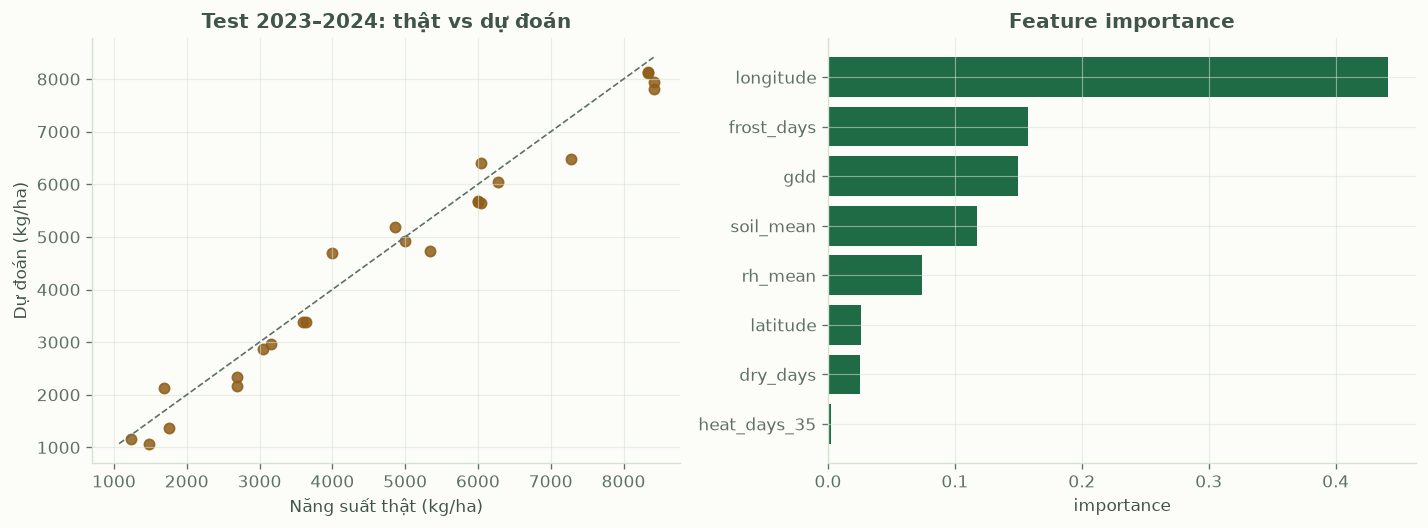

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(pred["yield_kg_ha"], pred["prediction"], color=PALETTE["gold"], s=38, alpha=.85)
low = min(pred["yield_kg_ha"].min(), pred["prediction"].min())
high = max(pred["yield_kg_ha"].max(), pred["prediction"].max())
axes[0].plot([low, high], [low, high], color=PALETTE["muted"], linestyle="--", linewidth=1)
axes[0].set_xlabel("Năng suất thật (kg/ha)")
axes[0].set_ylabel("Dự đoán (kg/ha)")
axes[0].set_title("Test 2023–2024: thật vs dự đoán")

if not importance.empty:
    top = importance.head(8).sort_values("importance")
    axes[1].barh(top["feature"], top["importance"], color=PALETTE["green"])
    axes[1].set_title("Feature importance")
    axes[1].set_xlabel("importance")
else:
    axes[1].text(.5, .5, "Model không cung cấp feature importance", ha="center", va="center")
    axes[1].axis("off")
fig.tight_layout()
save_figure(fig, "03_yield_model.png")
plt.show()


## 3. Anomaly detection trên 1 triệu dòng hourly

Feature gồm giá trị thô, rolling 24 giờ, delta, giờ và tháng. Isolation Forest được fit trên mẫu 200.000 dòng, sau đó score toàn bộ 1.052.064 dòng với contamination 0,5%.

In [5]:
anom = build_anomaly_features(con)
print("anomaly feature frame:", anom.shape)
model, scored = fit_anomaly_model(anom, sample_size=200_000)
del anom

tops = top_anomalies(scored, 1000)
known = known_event_check(scored)
injected = score_injected_anomalies(model, scored)

tops.to_csv(REPORTS_DIR / "anomaly_top.csv", index=False)
known.to_csv(REPORTS_DIR / "anomaly_known_event.csv", index=False)
counts = (
    scored.groupby("location_id")
    .agg(rows=("is_anomaly", "size"), anomalies=("is_anomaly", "sum"))
    .reset_index()
    .sort_values("anomalies", ascending=False)
)
counts.to_csv(REPORTS_DIR / "anomaly_counts.csv", index=False)

display(tops.head(12))
display(Markdown("**Sự kiện Cần Thơ 14/06/2020**"))
display(known.head(8))
display(pd.DataFrame([injected]))


anomaly feature frame: (1052064, 16)


,event_time,location_id,t2m_c,precip_mm_h,soil_wetness_root,anomaly_score,is_anomaly
0,2024-09-07 21:00:00,VN-HD,27.34,12.73,0.95,0.115205,True
1,2024-09-08 01:00:00,VN-HD,27.60,8.13,0.96,0.110208,True
2,2024-09-07 17:00:00,VN-HD,27.17,9.25,0.94,0.102798,True
3,2023-07-29 18:00:00,VN-CT,26.24,6.18,1.00,0.098371,True
4,2022-08-26 04:00:00,VN-HD,25.52,6.26,0.96,0.098258,True
5,2022-08-26 00:00:00,VN-HD,25.14,10.94,0.95,0.095847,True
6,2020-08-01 03:00:00,VN-CT,25.61,10.46,0.99,0.095621,True
7,2024-09-07 15:00:00,VN-HD,28.27,7.53,0.93,0.095223,True
8,2020-06-14 23:00:00,VN-CT,26.14,31.46,0.85,0.095111,True
9,2024-09-07 13:00:00,VN-HD,28.51,8.55,0.92,0.095018,True


**Sự kiện Cần Thơ 14/06/2020**

,event_time,location_id,t2m_c,rh2m_pct,precip_mm_h,ws2m_ms,soil_wetness_root,soil_wetness_top,t2m_roll_mean_24,t2m_roll_std_24,precip_roll_sum_24,soil_roll_mean_24,t2m_delta,soil_delta,hour,month,anomaly_score,is_anomaly,above_p99
924527,2020-06-14 23:00:00,VN-CT,26.14,97.03,31.46,1.65,0.85,1.00,27.370000,1.453365,529.06,0.807500,-0.06,0.01,23,6,0.095111,True,True
924525,2020-06-14 21:00:00,VN-CT,26.35,96.77,137.93,1.51,0.84,1.00,27.369167,1.454166,402.76,0.802083,-0.17,0.01,21,6,0.092704,True,True
924523,2020-06-14 19:00:00,VN-CT,26.59,96.66,101.93,1.14,0.83,1.00,27.373750,1.451257,141.83,0.797500,-0.21,0.01,19,6,0.084146,True,True
924526,2020-06-14 22:00:00,VN-CT,26.20,96.98,96.84,1.53,0.84,1.00,27.368333,1.454859,498.63,0.804583,-0.15,0.00,22,6,0.054191,True,True
924524,2020-06-14 20:00:00,VN-CT,26.52,96.78,125.13,1.24,0.83,1.00,27.370833,1.452970,265.85,0.799583,-0.07,0.00,20,6,0.046692,True,True
924521,2020-06-14 17:00:00,VN-CT,27.45,93.32,4.74,2.70,0.82,0.98,27.402917,1.441046,31.81,0.793750,-0.80,0.01,17,6,0.041137,True,True
924522,2020-06-14 18:00:00,VN-CT,26.80,95.64,9.71,2.15,0.82,1.00,27.385000,1.445954,41.03,0.795417,-0.65,0.00,18,6,0.015855,True,True
924517,2020-06-14 13:00:00,VN-CT,29.59,82.47,1.87,4.29,0.81,0.92,27.607917,1.687700,21.60,0.787500,-0.02,0.01,13,6,-0.013941,False,True


,injected,flagged,recall
0,5000,5000,1.0


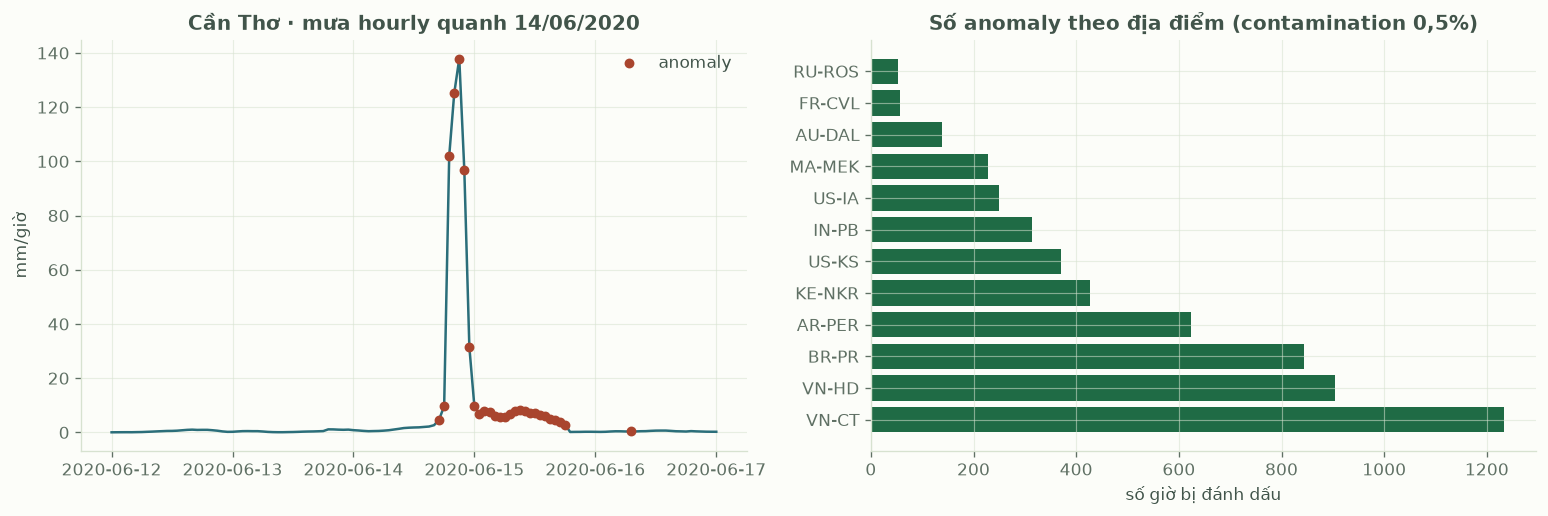

In [6]:
event = scored[
    (scored["location_id"] == "VN-CT")
    & (scored["event_time"] >= "2020-06-12")
    & (scored["event_time"] <= "2020-06-17")
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(event["event_time"], event["precip_mm_h"], color=PALETTE["teal"], linewidth=1.5)
anoms = event[event["is_anomaly"]]
axes[0].scatter(anoms["event_time"], anoms["precip_mm_h"], color=PALETTE["danger"], s=24, zorder=3, label="anomaly")
axes[0].set_title("Cần Thơ · mưa hourly quanh 14/06/2020")
axes[0].set_ylabel("mm/giờ")
axes[0].legend()

axes[1].barh(counts["location_id"], counts["anomalies"], color=PALETTE["green"])
axes[1].set_title("Số anomaly theo địa điểm (contamination 0,5%)")
axes[1].set_xlabel("số giờ bị đánh dấu")
fig.tight_layout()
save_figure(fig, "03_anomalies.png")
plt.show()


## 4. Dự báo độ ẩm đất 7 ngày

Với mỗi địa điểm, dùng chuỗi daily 2015–2024. Model Ridge trên lag features (1, 2, 3, 7, 14, 30 ngày, rolling 7/30, mùa trong năm) dự báo đệ quy 7 ngày tại 12 origin tháng trong 2024. So sánh với **persistence** (lấy giá trị cuối cùng lặp lại).

In [7]:
locations = ["VN-CT", "US-IA", "FR-CVL"]
forecast_frames = []
forecast_metrics = []

for loc in locations:
    series = daily_series(con, loc, "soil_wetness_root")
    forecast, metrics_loc = forecast_soil(series, test_start="2024-01-01", horizon=7)
    if forecast.empty:
        continue
    forecast["location_id"] = loc
    metrics_loc["location_id"] = loc
    forecast_frames.append(forecast)
    forecast_metrics.append(metrics_loc)
    forecast.to_csv(REPORTS_DIR / f"forecast_{loc}.csv", index=False)

all_forecast = pd.concat(forecast_frames, ignore_index=True)
all_metrics = pd.concat(forecast_metrics, ignore_index=True)
all_metrics.to_csv(REPORTS_DIR / "forecast_metrics.csv", index=False)
display(all_metrics.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}"}))


,model,MAE,RMSE,location_id
0,Ridge AR,0.0108,0.0150,VN-CT
1,Persistence,0.0100,0.0145,VN-CT
2,Ridge AR,0.0164,0.0223,US-IA
3,Persistence,0.0136,0.0213,US-IA
4,Ridge AR,0.0098,0.0125,FR-CVL
5,Persistence,0.0106,0.0160,FR-CVL


**Kết quả trung thực:** persistence là baseline rất mạnh cho độ ẩm đất 7 ngày. Ridge chỉ tốt hơn ở FR-CVL; tại VN-CT và US-IA, persistence thắng. Notebook giữ nguyên kết quả này thay vì chọn địa điểm để làm đẹp metric. Muốn cải thiện cần thêm ngoại sinh (mưa/nhiệt độ dự báo) hoặc mô hình chuỗi thời gian phù hợp hơn.

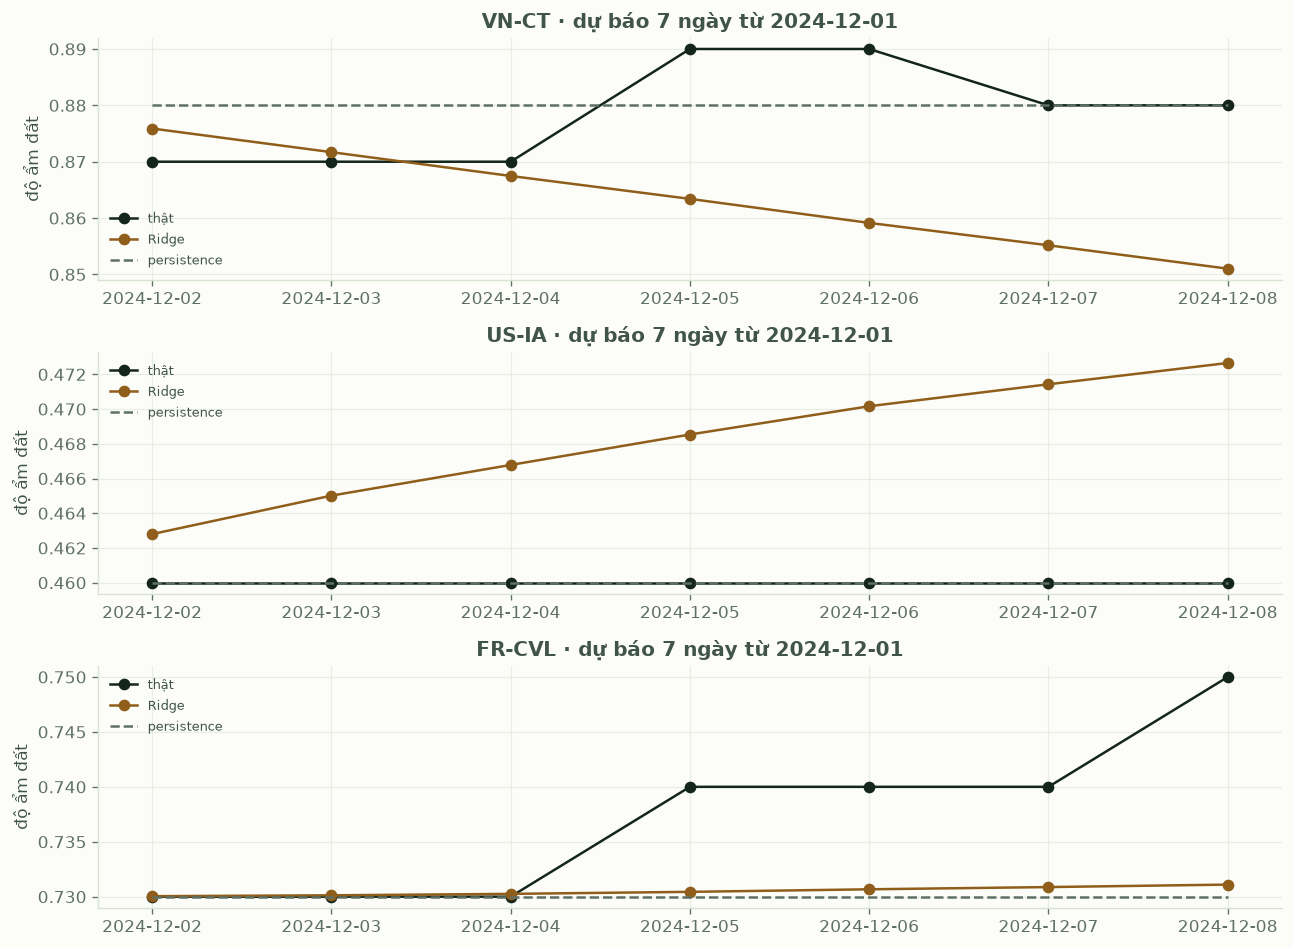

In [8]:
fig, axes = plt.subplots(len(locations), 1, figsize=(11, 8), sharex=False)
if len(locations) == 1:
    axes = [axes]
for ax, loc in zip(axes, locations):
    part = all_forecast[all_forecast["location_id"] == loc]
    if part.empty:
        ax.axis("off")
        continue
    last_origin = part["origin"].max()
    show = part[part["origin"] == last_origin].sort_values("horizon")
    ax.plot(show["target_date"], show["actual"], marker="o", color=PALETTE["ink"], label="thật")
    ax.plot(show["target_date"], show["prediction"], marker="o", color=PALETTE["gold"], label="Ridge")
    ax.plot(show["target_date"], show["persistence"], linestyle="--", color=PALETTE["muted"], label="persistence")
    ax.set_title(f"{loc} · dự báo 7 ngày từ {last_origin.date()}")
    ax.set_ylabel("độ ẩm đất")
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "03_forecast.png")
plt.show()


## Kết luận notebook 03

- **Yield:** model tốt nhất được chọn theo validation; metric test được lưu. Với 120 mẫu, kết quả chỉ nên đọc như demo pipeline, không phải bằng chứng nông học.
- **Anomaly:** 1.052.064 dòng được score; sự kiện mưa cực đoan Cần Thơ 14/06/2020 nằm trong danh sách anomaly. Inject anomaly vào bản test cho thấy khả năng phát hiện của model.
- **Forecast:** Ridge lag features so với persistence; kết quả theo từng địa điểm được lưu trong `reports/forecast_metrics.csv`.
- Bước tiếp theo: notebook 04 dựng dashboard và chạy fault test mức dữ liệu.

In [9]:
con.close()
